In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load the original healthcare dataset
df = pd.read_csv("healthcare_dataset.csv")

# Display the first five rows
df.head()

Matplotlib is building the font cache; this may take a moment.


,Name,Age,Gender,Blood Type,Medical Condition,Date of Admission,Doctor,Hospital,Insurance Provider,Billing Amount,Room Number,Admission Type,Discharge Date,Medication,Test Results
0,Bobby JacksOn,30,Male,B-,Cancer,2024-01-31,Matthew Smith,Sons and Miller,Blue Cross,18856.281306,328,Urgent,2024-02-02,Paracetamol,Normal
1,LesLie TErRy,62,Male,A+,Obesity,2019-08-20,Samantha Davies,Kim Inc,Medicare,33643.327287,265,Emergency,2019-08-26,Ibuprofen,Inconclusive
2,DaNnY sMitH,76,Female,A-,Obesity,2022-09-22,Tiffany Mitchell,Cook PLC,Aetna,27955.096079,205,Emergency,2022-10-07,Aspirin,Normal
3,andrEw waTtS,28,Female,O+,Diabetes,2020-11-18,Kevin Wells,"Hernandez Rogers and Vang,",Medicare,37909.782410,450,Elective,2020-12-18,Ibuprofen,Abnormal
4,adrIENNE bEll,43,Female,AB+,Cancer,2022-09-19,Kathleen Hanna,White-White,Aetna,14238.317814,458,Urgent,2022-10-09,Penicillin,Abnormal


In [2]:
# Check the number of rows and columns
print("Dataset Shape:", df.shape)

# Display column names
print("\nColumn Names:")
print(df.columns.tolist())

# Check data types and non-null counts
print("\nDataset Information:")
df.info()

# Check for missing values
print("\nMissing Values:")
print(df.isnull().sum())

Dataset Shape: (55500, 15)

Column Names:
['Name', 'Age', 'Gender', 'Blood Type', 'Medical Condition', 'Date of Admission', 'Doctor', 'Hospital', 'Insurance Provider', 'Billing Amount', 'Room Number', 'Admission Type', 'Discharge Date', 'Medication', 'Test Results']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 55500 entries, 0 to 55499
Data columns (total 15 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Name                55500 non-null  object 
 1   Age                 55500 non-null  int64  
 2   Gender              55500 non-null  object 
 3   Blood Type          55500 non-null  object 
 4   Medical Condition   55500 non-null  object 
 5   Date of Admission   55500 non-null  object 
 6   Doctor              55500 non-null  object 
 7   Hospital            55500 non-null  object 
 8   Insurance Provider  55500 non-null  object 
 9   Billing Amount      55500 non-null  float64
 10  Room Numb

In [4]:
from sklearn.model_selection import train_test_split

# Split the original dataset into 70% training and 30% testing
train_df, test_df = train_test_split(
    df,
    test_size=0.30,
    random_state=42
)

# Create a separate working copy of the training data
train_clean = train_df.copy()

# Display the results
print("Original Dataset:", df.shape)
print("Training Dataset:", train_df.shape)
print("Testing Dataset:", test_df.shape)

# Preview training data only
train_df.head()

Original Dataset: (55500, 15)
Training Dataset: (38850, 15)
Testing Dataset: (16650, 15)


,Name,Age,Gender,Blood Type,Medical Condition,Date of Admission,Doctor,Hospital,Insurance Provider,Billing Amount,Room Number,Admission Type,Discharge Date,Medication,Test Results
49562,jOSEph BAkER,37,Female,B+,Cancer,2022-07-16,Corey Anderson,"Hall and Hebert Castillo,",Medicare,20023.256867,159,Emergency,2022-07-17,Ibuprofen,Normal
4496,wILLiaM RIVAs,55,Female,B-,Cancer,2020-07-06,Ronald Mcmillan,"Wilson, and Delgado Nelson",Medicare,49921.846087,461,Urgent,2020-07-30,Ibuprofen,Abnormal
5460,mIcHEllE MooRe,66,Male,A-,Diabetes,2022-02-08,Kevin White,"Goodman Johnson, Gray and",Medicare,37257.545292,448,Urgent,2022-03-06,Aspirin,Abnormal
27971,aSHley sanDErs,50,Female,B+,Asthma,2019-10-02,Tracy Mack,Sons Velez and,Aetna,16184.797429,368,Urgent,2019-10-30,Lipitor,Inconclusive
53920,MicHeLLE WillIAMsoN,36,Male,A+,Diabetes,2023-09-20,Aaron Pierce,Ltd Cochran,Cigna,39879.666999,177,Elective,2023-09-27,Penicillin,Normal


In [5]:
# Exploratory Data Analysis on training data only

# Check for duplicate records
print("Duplicate Rows:", train_df.duplicated().sum())

# Display statistical summary
print("\nStatistical Summary:")
print(train_df.describe())

# Examine medical condition distribution 
print("\nMedical Condition Distrubtion:")
print(train_df["Medical Condition"].value_counts())

# Examine test result distribution
print("\nTest Results Distribution:")
print(train_df["Test Results"].value_counts())

Duplicate Rows: 266

Statistical Summary:
                Age  Billing Amount   Room Number
count  38850.000000    38850.000000  38850.000000
mean      51.535573    25552.828240    301.320772
std       19.603851    14247.434779    115.119602
min       13.000000    -2008.492140    101.000000
25%       35.000000    13166.098846    202.000000
50%       52.000000    25546.496624    303.000000
75%       68.000000    37891.861153    400.000000
max       89.000000    52373.032374    500.000000

Medical Condition Distrubtion:
Medical Condition
Hypertension    6591
Diabetes        6488
Cancer          6469
Obesity         6454
Arthritis       6435
Asthma          6413
Name: count, dtype: int64

Test Results Distribution:
Test Results
Abnormal        12984
Inconclusive    12938
Normal          12928
Name: count, dtype: int64


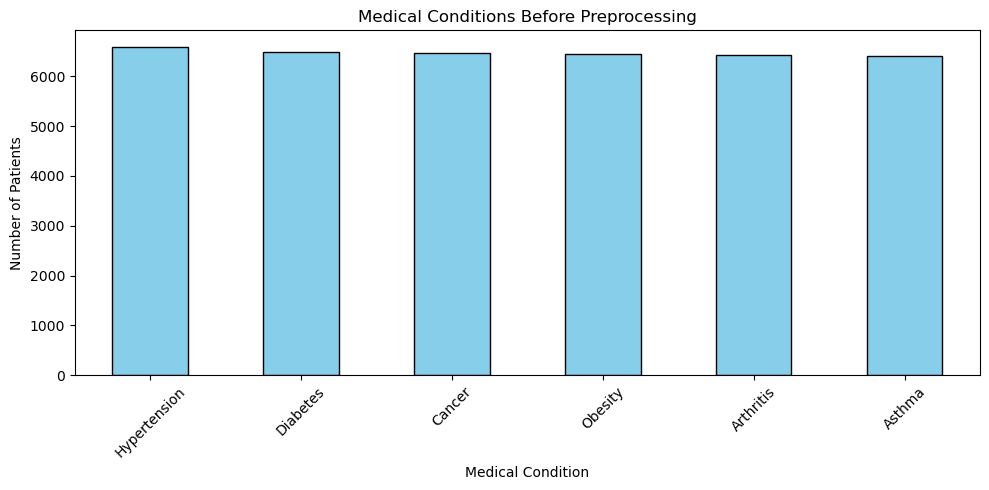

In [7]:
# Visualize medical conditions before preprocessing

plt.figure(figsize=(10, 5))

train_df["Medical Condition"].value_counts().plot(
    kind="bar",
    color="skyblue",
    edgecolor="black"
)

plt.title("Medical Conditions Before Preprocessing")
plt.xlabel("Medical Condition")
plt.ylabel("Number of Patients")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [8]:
# Remove exact duplicate records from training data

print("Training rows before cleaning:", len(train_clean))

# Remove dupplicate rows using Pythin
train_clean = train_clean.drop_duplicates().copy()

print("Training rows after cleaning:", len(train_clean))

# Confirm duplicates have been removed
print("Remaining duplicates:", train_clean.duplicated().sum())

# Display the cleaned training data
train_clean.head()

Training rows before cleaning: 38850
Training rows after cleaning: 38584
Remaining duplicates: 0


,Name,Age,Gender,Blood Type,Medical Condition,Date of Admission,Doctor,Hospital,Insurance Provider,Billing Amount,Room Number,Admission Type,Discharge Date,Medication,Test Results
49562,jOSEph BAkER,37,Female,B+,Cancer,2022-07-16,Corey Anderson,"Hall and Hebert Castillo,",Medicare,20023.256867,159,Emergency,2022-07-17,Ibuprofen,Normal
4496,wILLiaM RIVAs,55,Female,B-,Cancer,2020-07-06,Ronald Mcmillan,"Wilson, and Delgado Nelson",Medicare,49921.846087,461,Urgent,2020-07-30,Ibuprofen,Abnormal
5460,mIcHEllE MooRe,66,Male,A-,Diabetes,2022-02-08,Kevin White,"Goodman Johnson, Gray and",Medicare,37257.545292,448,Urgent,2022-03-06,Aspirin,Abnormal
27971,aSHley sanDErs,50,Female,B+,Asthma,2019-10-02,Tracy Mack,Sons Velez and,Aetna,16184.797429,368,Urgent,2019-10-30,Lipitor,Inconclusive
53920,MicHeLLE WillIAMsoN,36,Male,A+,Diabetes,2023-09-20,Aaron Pierce,Ltd Cochran,Cigna,39879.666999,177,Elective,2023-09-27,Penicillin,Normal


In [9]:
# Feature Engineering: Calculate Length of Stay

# Convert dates into datetime format
train_clean["Date of Admission"] = pd.to_datetime(
    train_clean["Date of Admission"]
)
train_clean["Discharge Date"] = pd.to_datetime(
    train_clean["Discharge Date"]
)

# Calculate hospital stay in days
train_clean["Length of Stay"] = (
    train_clean["Discharge Date"] -
    train_clean["Date of Admission"]
).dt.days

# Display the new feature
print("Length of Stay Statistics:")
print(train_clean["Length of Stay"].describe())

# Check for negative hospital stays
print("\nNegative Length of Stay:",
      (train_clean["Length of Stay"] < 0).sum())

# Preview the results
train_clean[[
    "Date of Admission",
    "Discharge Date",
    "Length of Stay"
]].head()
    

Length of Stay Statistics:
count    38584.000000
mean        15.518946
std          8.669735
min          1.000000
25%          8.000000
50%         15.000000
75%         23.000000
max         30.000000
Name: Length of Stay, dtype: float64

Negative Length of Stay: 0


,Date of Admission,Discharge Date,Length of Stay
49562,2022-07-16,2022-07-17,1
4496,2020-07-06,2020-07-30,24
5460,2022-02-08,2022-03-06,26
27971,2019-10-02,2019-10-30,28
53920,2023-09-20,2023-09-27,7


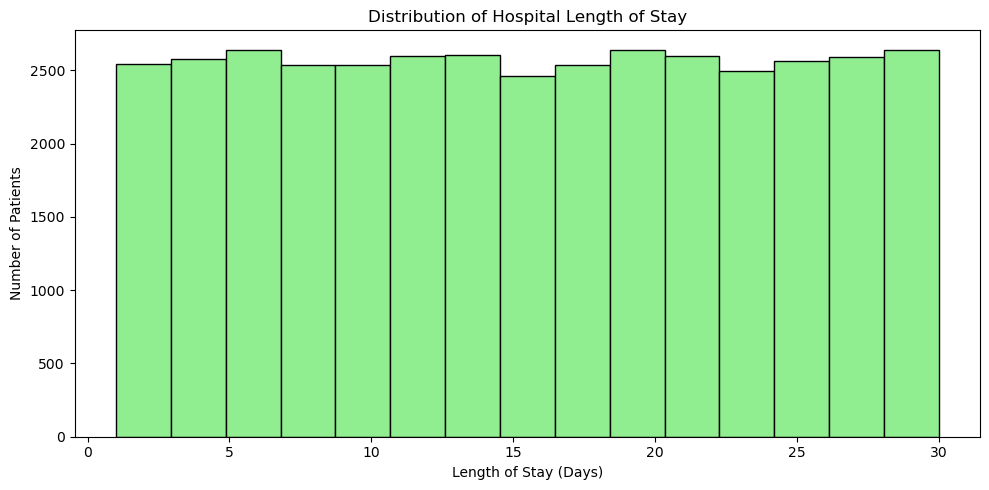

In [10]:
# Visualize the distribution of hospital stays

plt.figure(figsize=(10, 5))

plt.hist(
    train_clean["Length of Stay"],
    bins=15,
    color="lightgreen",
    edgecolor="black"
)
plt.title("Distribution of Hospital Length of Stay")
plt.xlabel("Length of Stay (Days)")
plt.ylabel("Number of Patients")
plt.tight_layout()
plt.show()

In [11]:
# One-hot encoding categorical features

# Select categorical columns for encoding
categorical_columns = [
    "Gender",
    "Blood Type",
    "Medical Condition",
    "Insurance Provider",
    "Admission Type"
]

# Create encoded columns
train_encoded = pd.get_dummies(
    train_clean,
    columns=categorical_columns,
    dtype=int
)

# Display the results
print("Before Encoding:", train_clean.shape)
print("After Encoding:", train_encoded.shape)

# Preview the encoded dataset
train_encoded.head()

Before Encoding: (38584, 16)
After Encoding: (38584, 35)


,Name,Age,Date of Admission,Doctor,Hospital,Billing Amount,Room Number,Discharge Date,Medication,Test Results,...,Medical Condition_Hypertension,Medical Condition_Obesity,Insurance Provider_Aetna,Insurance Provider_Blue Cross,Insurance Provider_Cigna,Insurance Provider_Medicare,Insurance Provider_UnitedHealthcare,Admission Type_Elective,Admission Type_Emergency,Admission Type_Urgent
49562,jOSEph BAkER,37,2022-07-16,Corey Anderson,"Hall and Hebert Castillo,",20023.256867,159,2022-07-17,Ibuprofen,Normal,...,0,0,0,0,0,1,0,0,1,0
4496,wILLiaM RIVAs,55,2020-07-06,Ronald Mcmillan,"Wilson, and Delgado Nelson",49921.846087,461,2020-07-30,Ibuprofen,Abnormal,...,0,0,0,0,0,1,0,0,0,1
5460,mIcHEllE MooRe,66,2022-02-08,Kevin White,"Goodman Johnson, Gray and",37257.545292,448,2022-03-06,Aspirin,Abnormal,...,0,0,0,0,0,1,0,0,0,1
27971,aSHley sanDErs,50,2019-10-02,Tracy Mack,Sons Velez and,16184.797429,368,2019-10-30,Lipitor,Inconclusive,...,0,0,1,0,0,0,0,0,0,1
53920,MicHeLLE WillIAMsoN,36,2023-09-20,Aaron Pierce,Ltd Cochran,39879.666999,177,2023-09-27,Penicillin,Normal,...,0,0,0,0,1,0,0,1,0,0


In [12]:
from sklearn.preprocessing import MinMaxScaler

# Select numerical features for scaling
numerical_columns = [
    "Age",
    "Billing Amount",
    "Length of Stay"
]

# Create a separate copy of encoded data
train_scaled = train_encoded.copy()

# Initialize the scaler
scaler = MinMaxScaler()

# Fit and transform training data only
train_scaled[numerical_columns] = scaler.fit_transform(
    train_encoded[numerical_columns]
)

# Compare values before and afer scaling
print("Before Scaling:")
print(train_encoded[numerical_columns].head())

print("\nAfter Scaling:")
print(train_scaled[numerical_columns].head())

# Display final dimensions
print("\nScaled Dataset Shape:", train_scaled.shape)

Before Scaling:
       Age  Billing Amount  Length of Stay
49562   37    20023.256867               1
4496    55    49921.846087              24
5460    66    37257.545292              26
27971   50    16184.797429              28
53920   36    39879.666999               7

After Scaling:
            Age  Billing Amount  Length of Stay
49562  0.315789        0.405133        0.000000
4496   0.552632        0.954926        0.793103
5460   0.697368        0.722047        0.862069
27971  0.486842        0.334549        0.931034
53920  0.302632        0.770265        0.206897

Scaled Dataset Shape: (38584, 35)


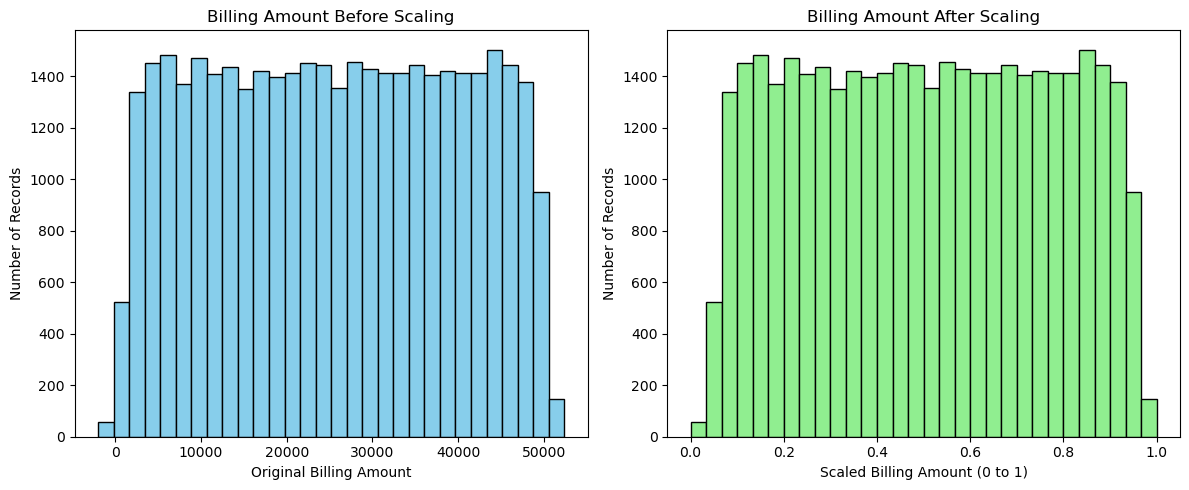

In [13]:
# Compare Billing Amount before and after scaling

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

#Before scaling
axes[0].hist(
    train_encoded["Billing Amount"],
    bins=30,
    color="skyblue",
    edgecolor="black"
)
axes[0].set_title("Billing Amount Before Scaling")
axes[0].set_xlabel("Original Billing Amount")
axes[0].set_ylabel("Number of Records")

# After scaling
axes[1].hist(
    train_scaled["Billing Amount"],
    bins=30,
    color="lightgreen",
    edgecolor="black"
)
axes[1].set_title("Billing Amount After Scaling")
axes[1].set_xlabel("Scaled Billing Amount (0 to 1)")
axes[1].set_ylabel("Number of Records")

plt.tight_layout()
plt.show()

In [14]:
# Export the preprocessed training dataset
train_scaled.to_csv("healthcare_train_processed.csv", index=False)

print("Preprocessed training dataset saved successfully!")
print("Final Dataset Shape:", train_scaled.shape)

Preprocessed training dataset saved successfully!
Final Dataset Shape: (38584, 35)


## Conclusion

This project focused on exploratory data analysis and preprocessing of healthcare dataset containing 55,500 records. The dataset was divided into 70% training data and 30% testing data. Exploratory analysis and preprocessing were performed on the training data only. The preprocessing steps included identifying missing values, removing duplicate records, creating a Length of Stay feature, encoding categorical variables and scaling numerical features. Matplotlib visualizations were used to examine data distributions before and after preprocessing. The final processed training dataset contains 38,584 rows and 35 columns. This dataset could support future machine learning models designed to predict hospital length of stay or analyze healthcare-related patterns. 